# Formats

One drawing exported to many formats and read back. `doc.save(path)` picks the exporter from the extension
and `Document.open(path)` the importer, so the same drawing travels through vector, raster, document, TeX
and CAD files.

Run it as ``python 07_formats.py`` or open ``07_formats.ipynb`` to see each step.

In [1]:
import importlib.util
import warnings
from pathlib import Path

import svgwriter as svg

A small drawing with a gradient, a shape, a polyline and a line of text. Everything below is
written from this one `Document`.

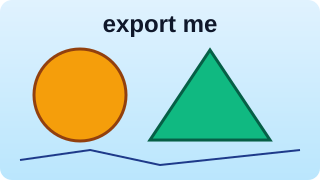

In [2]:
WIDTH, HEIGHT = 320, 180
doc = svg.Document(WIDTH, HEIGHT)
doc.title("Formats")
doc.rect(0, 0, WIDTH, HEIGHT, rx=12, fill=svg.LinearGradient.vertical("#e0f2fe", "#bae6fd"))
doc.circle(80, 95, 46, fill="#f59e0b", stroke="#92400e", stroke_width=3)
doc.polygon([(150, 140), (210, 50), (270, 140)], fill="#10b981", stroke="#065f46", stroke_width=3)
doc.polyline([(20, 160), (90, 150), (160, 165), (300, 150)], fill="none", stroke="#1e3a8a", stroke_width=2)
doc.text("export me", x=WIDTH / 2, y=32, font_size=24, font_family="Arial, Helvetica, sans-serif",
         font_weight="bold", text_anchor="middle", fill="#0f172a")
doc

Save SVG and PNG. A PNG is pixels, so text becomes
pixels too; the SVG keeps it as text.

In [3]:
formats = Path("formats")
formats.mkdir(exist_ok=True)

doc.save("07_formats.svg")
doc.save(formats / "drawing.svg")
doc.save(formats / "drawing.png", scale=2)
print("svg and png:", ", ".join(sorted(path.name for path in formats.iterdir())))

svg and png: drawing.png, drawing.svg


## Text-keeping formats

PDF, EPS and TikZ keep text as text, so it stays selectable in a viewer or searchable in the source.
The TikZ file is a `tikzpicture` of `\draw` and `\node` commands; `standalone=True` makes it compilable.

In [4]:
doc.save(formats / "drawing.pdf")
doc.save(formats / "drawing.eps")
doc.save(formats / "drawing.tikz")
tikz = (formats / "drawing.tikz").read_text(encoding="utf-8")
print("\\node in TikZ:", [line.strip() for line in tikz.splitlines() if "\\node" in line][:1])
print("text in PDF:", b"/Font" in (formats / "drawing.pdf").read_bytes())

\node in TikZ: ['\\node[anchor=base west, inner sep=0pt, outer sep=0pt, font=\\fontsize{18.067}{21.681}\\selectfont\\sffamily\\bfseries, text=svgc7] at (102.648,32) {export me};']
text in PDF: True


PowerPoint (editable shapes and text boxes, needs `pysvgwriter[office]`) and DXF (CAD polylines in
millimetres, one layer per colour). Exporters that need an optional package are skipped when it is missing.

In [5]:
if importlib.util.find_spec("pptx") is not None:
    doc.save(formats / "drawing.pptx")
doc.save(formats / "drawing.dxf")
print(", ".join(sorted(path.name for path in formats.iterdir())))

drawing.dxf, drawing.eps, drawing.pdf, drawing.png, drawing.pptx, drawing.svg, drawing.tikz


## Reading back

`Document.open` reads files back (TikZ is shown above as source). Text-keeping formats return `<text>`
elements again, DXF returns polylines only and PNG a single `<image>`. Counting elements of each kind
shows what every format preserved.

In [6]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for path in sorted(formats.iterdir()):
        if path.suffix == ".tikz":
            continue
        back = svg.Document.open(path)
        texts = back.root.find_all("text")
        shapes = sum(len(back.root.find_all(tag)) for tag in ("path", "polygon", "polyline", "rect", "circle", "line"))
        images = len(back.root.find_all("image"))
        rows.append((path.name, len(texts), shapes, images))
for name, texts, shapes, images in rows:
    print(f"{name:14} text={texts:<3} shapes={shapes:<4} images={images}")

drawing.dxf    text=0   shapes=16   images=0
drawing.eps    text=1   shapes=4    images=0
drawing.pdf    text=1   shapes=4    images=0
drawing.png    text=0   shapes=0    images=1
drawing.pptx   text=1   shapes=4    images=0
drawing.svg    text=1   shapes=4    images=0


The PDF read back is a drawing again: shapes, a gradient and the text, ready to edit and save as SVG.

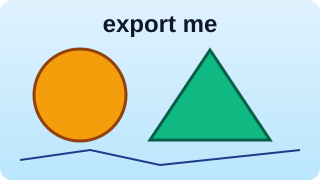

In [7]:
svg.Document.open(formats / "drawing.pdf")

## Print sizes and units

`size="a6-landscape"` makes a postcard in millimetres: the `viewBox` counts in mm, so plain numbers
below are millimetres. Lengths in other units convert with `.to("mm")`, angles take `svg.deg` or
`svg.turn`, and `dpi=` renders the real size at print resolution.

viewBox: ViewBox(min_x=0, min_y=0, width=148.0, height=105.0) | width: 148mm


postcard.png at 300 dpi: 1750 px wide


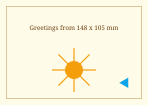

In [8]:
card = svg.Document(size="a6-landscape")
card_width, card_height = (side.value for side in svg.page_size("a6-landscape"))
margin = svg.inch(0.25).to("mm").value
title_size = svg.pt(18).to("mm").value
card.rect(0, 0, card_width, card_height, fill="#fefce8")
card.rect(margin, margin, card_width - 2 * margin, card_height - 2 * margin, fill="none", stroke="#a16207",
          stroke_width=svg.pt(1).to("mm").value)
card.text("Greetings from 148 x 105 mm", x=card_width / 2, y=30, font_size=title_size,
          font_family="Georgia, serif", text_anchor="middle", fill="#713f12")
for index in range(8):
    ray = svg.rect(card_width / 2 - 0.6, 48, 1.2, 22, fill="#f59e0b")
    card += ray.rotate(svg.turn(index / 8), about=(card_width / 2, 70))
card.circle(card_width / 2, 70, 9, fill="#f59e0b")
card += svg.Polygon.regular(card_width - 22, card_height - 22, 6, 3, fill="#0ea5e9").rotate(svg.deg(30))
card.save(formats / "postcard.png", dpi=300)
print("viewBox:", card.root.get("viewBox"), "| width:", card.root.get("width"))
print("postcard.png at 300 dpi:", svg.Document.open(formats / "postcard.png").root.get("width"), "px wide")
card